# 21 — Beyond points per game: are our rules really about scoring?

**In brief**
- **Question:** charts use points per game because every reader knows it. But several of our rules are *defined* on points alone. Would an all-round measure (game score, usage) do the same job better?
- **Answer:** for the turning point (D27), only a little. In the live race a turning point on **game score** beat points by the rule written in advance (2 of 3 points of the season), so the live race now uses it (D41); before the season, points stayed. Points and game score are nearly the same measure for established players (correlation 0.955): voters discount *established* players, however that standing was earned.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D41 (from 21B). Later sections will test D29, D33, the notebook 18 lookalikes and "already clearly a star" (TODO, B2b).
- **Where it fits:** Phase B of the plan (TODO). It checks the Most Improved models (11, 12) rather than adding a new one.
- **Dated:** 21A–21B written 12 November 2026; further sections to follow.

**In detail.** Phase B has five steps: an inventory of what every model and rule uses (21A); all-round versions of the four points-defined rules (21B onwards, one rule at a time); more metrics in the models; plain captions; and decisions. This notebook starts with the inventory and the **scoring turning point** (D27), because it sits in both Most Improved models and carries one of the largest weights.

## 21A — What every model and rule uses (B1)

| Part of the project | Inputs | Role of points per game |
|---|---|---|
| **Live race** (in-season Most Improved, notebook 12) | Changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team's change in winning; age; second year; baseline points (with the turning point); already an All-Star; back from a lost season | One input of 17, but with the largest weight |
| **Preseason Most Improved** (notebook 11) | Last season's minutes, points, usage and team wins; age, second year, new team; last season's trend and finish; preseason production, shot volume and shooting per 36; the turning point; a 20-point scorer left; already an All-Star; back from a lost season | One input of 16 |
| **Breakout models** (notebook 06) | 197 features: level, trend and change of every box-score, shooting, style and role measure, career and draft information | One of many |
| **Star score** (notebook 05) | Six equal pillars: scoring, creation, rebounding, defence, impact, trust | One pillar of six |
| **Playing-style clusters** (notebook 13) | 15 style measures | Not used, by design |
| **Unicorn scores** (notebook 04) | Rarity of skill combinations and distance to similar players, from style and body measures | Not used |
| **Scoring turning point** (D27) | Last season's points above 20 | **The definition**: tested in 21B |
| **"A 20-point scorer left"** (D29) | The departed player's points | **The definition** |
| **The blip test and leaps** (D33, notebook 16) | Share of the points jump kept | **The definition** (kept on points for Alexander-Walker, as written in advance) |
| **Ty Jerome lookalikes** (notebook 18) | Up 8+ points at day 19 | **The definition** |

The models already use many measures. The **rules that shape them** are where points stand alone, so those are tested one at a time.

The cell below prints each Most Improved model's inputs straight from the code, so this table cannot drift from what is actually used.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.hot_start import add_stale
from unicorn.labels import MIP_WINNERS
from unicorn.mip_eval import LIVE_INPUTS, POINTS_INPUTS, current_frame, scorecard, turning_point_ranks
from unicorn.plotting import FIG_DIR, INK, INK2, MUTED, SERIES, SURFACE, apply_style
from unicorn.preseason import USED, TURN, add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
sel = load_selections()
print("live race inputs:", LIVE_INPUTS)
print("preseason inputs:", USED)

live race inputs: ['ppg_delta', 'rpg_delta', 'apg_delta', 'mpg_delta', 'game_score_delta', 'ts_delta', 'spg_delta', 'bpg_delta', 'ppg_rel', 'game_score_rel', 'team_win_delta', 'age', 'second_year', 'base_game_score', 'over_turn', 'prior_allstar', 'stale']
preseason inputs: ['mpg_last', 'ppg_last', 'usg_last', 'team_win_pct_last', 'age', 'second_year', 'new_team', 'momentum_game_score', 'late_surge_last', 'pre_game_score_change', 'pre_volume_change', 'pre_ts_change', 'ppg_over_turn', 'star_left', 'prior_allstar', 'stale']


## 21B — The scoring turning point: points, game score or usage? (D27)

**The rule today.** Last season's scoring counts *for* a candidate up to 20 points a game and *against* him above it: established scorers are MVP material, not Most Improved. No winner since 2000-01 had scored more than 20.3 the season before.

**The question.** Is it really *scoring* that voters hold against established players, or being an established, all-round high-level player? If the second, a turning point on **game score** (all-round production) or **usage** (share of the offence) should fit better.

**Variants** (the measure gets both the straight input and the turning point, unless marked "turning point only"):

| Model | Variant | Straight input | Turning point on |
|---|---|---|---|
| In-season | **points** (current) | baseline points | baseline points |
| In-season | game score | baseline game score | baseline game score |
| In-season | game score, turning point only | baseline points | baseline game score |
| Preseason | **points** (current) | last season's points | last season's points |
| Preseason | game score | last season's game score | last season's game score |
| Preseason | game score, turning point only | last season's points | last season's game score |
| Preseason | usage | last season's usage (already an input) | last season's usage |
| Preseason | usage, turning point only | last season's points | last season's usage |

Usage is only tested before the season: the game logs behind the in-season model have no usage.

**A fair contest.** Each measure gets a grid of five turning points placed at the **same percentiles of candidates** as 16–24 points (game score 12.5–18.5; usage 23.5–29%), plus "no turning point". The turning point is **chosen inside each training set** by season-grouped cross-validation, as the live race does (D32), so no variant is tuned on the season it is tested on.

**The rule for deciding, written before the results:** a measure replaces points only if it improves × a blind guess in the **strict** test at most of the points tested, without lowering how often the winner is in our top 7. Ties keep points.

In [2]:
# in-season: every past season (2000-01 → 2025-26) at day 19, day 85 and the end of the season
g = MH.load_games(); info = MH.player_info(); votes, winners = MH.voting(g)
POINTS_OF_SEASON = {"day 19": 19, "day 85": 85, "end of season": None}
INS = {k: current_frame(g, info, winners, sel, day=d, turn=None) for k, d in POINTS_OF_SEASON.items()}

# preseason: 2012-13 → 2025-26 (preseason game logs start in 2012-13)
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)
F = add_stale(add_prior_allstar(add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, regular, ps), MIP_WINNERS)), pre, regular), sel))
PRE = F[F["season"] != "2026-27"].reset_index(drop=True)

GRID = {"points": (None, 16, 18, 20, 22, 24), "game score": (None, 12.5, 14, 15.5, 17, 18.5), "usage": (None, 0.235, 0.25, 0.265, 0.28, 0.29)}
BASE_IN = [c for c in POINTS_INPUTS if c not in ("base_ppg", "over_turn")]   # the model without its scoring level, as it stood before this test
BASE_PRE = [c for c in USED if c not in TURN + ["ppg_last"]]
IN_VARIANTS = {   # name: (inputs without the turning point, turning point on, grid)
    "points (current)": (BASE_IN + ["base_ppg"], "base_ppg", GRID["points"]),
    "game score": (BASE_IN + ["base_game_score"], "base_game_score", GRID["game score"]),
    "game score, turning point only": (BASE_IN + ["base_ppg"], "base_game_score", GRID["game score"]),
}
PRE_VARIANTS = {
    "points (current)": (BASE_PRE + ["ppg_last"], "ppg_last", GRID["points"]),
    "game score": (BASE_PRE + ["gspg_last"], "gspg_last", GRID["game score"]),
    "game score, turning point only": (BASE_PRE + ["ppg_last"], "gspg_last", GRID["game score"]),
    "usage": (BASE_PRE, "usg_last", GRID["usage"]),
    "usage, turning point only": (BASE_PRE + ["ppg_last"], "usg_last", GRID["usage"]),
}
print({k: f"{len(v):,} candidates, {v['season'].nunique()} seasons" for k, v in INS.items()})
print(f"preseason: {len(PRE):,} candidates, {PRE['season'].nunique()} seasons")

{'day 19': '7,057 candidates, 26 seasons', 'day 85': '7,331 candidates, 26 seasons', 'end of season': '7,509 candidates, 26 seasons'}
preseason: 5,230 candidates, 14 seasons


In [3]:
# run every variant in both tests; the turning point is chosen inside each training set
rows = []
def run(model, point, frame, variants):
    for name, (feats, level, grid) in variants.items():
        for scheme in ["strict", "leave-one-out"]:
            r = turning_point_ranks(frame, feats, level, grid, scheme=scheme)
            k = r["k"].astype(object).where(r["k"].notna(), "none").value_counts()
            rows.append({"model": model, "point": point, "variant": name, "test": scheme, **scorecard(r),
                         "turning point chosen (most often)": f"{k.index[0]} ({k.iloc[0]} of {len(r)})"})
for point, frame in INS.items():
    run("in-season", point, frame, IN_VARIANTS)
run("preseason", "before the season", PRE, PRE_VARIANTS)
R = pd.DataFrame(rows)
SHOW = ["× a blind guess", "in top 7", "median rank", "winner #1", "turning point chosen (most often)"]
for test in ["strict", "leave-one-out"]:
    print(test.upper())
    display(R[R["test"] == test].set_index(["model", "point", "variant"])[["seasons"] + SHOW]
            .style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}))

STRICT


LEAVE-ONE-OUT


In [4]:
# the decision rule, applied: does any variant beat points in the strict test at most points, without fewer winners in the top 7?
strict = R[R["test"] == "strict"].set_index(["model", "point", "variant"])
verdict = []
for model, variants in [("in-season", IN_VARIANTS), ("preseason", PRE_VARIANTS)]:
    pts = strict.xs((model, "points (current)"), level=["model", "variant"])
    for name in variants:
        if name == "points (current)":
            continue
        v = strict.xs((model, name), level=["model", "variant"])
        better = (v["× a blind guess"] > pts["× a blind guess"]) & (v["in top 7"] >= pts["in top 7"])
        verdict.append({"model": model, "variant": name, "points of the season tested": len(v),
                        "better than points (strict, no fewer in top 7)": int(better.sum()),
                        "replaces points?": "yes" if better.sum() > len(v) / 2 else "no"})
pd.DataFrame(verdict).style.hide(axis="index")

model,variant,points of the season tested,"better than points (strict, no fewer in top 7)",replaces points?
in-season,game score,3,2,yes
in-season,"game score, turning point only",3,1,no
preseason,game score,1,0,no
preseason,"game score, turning point only",1,0,no
preseason,usage,1,0,no
preseason,"usage, turning point only",1,0,no


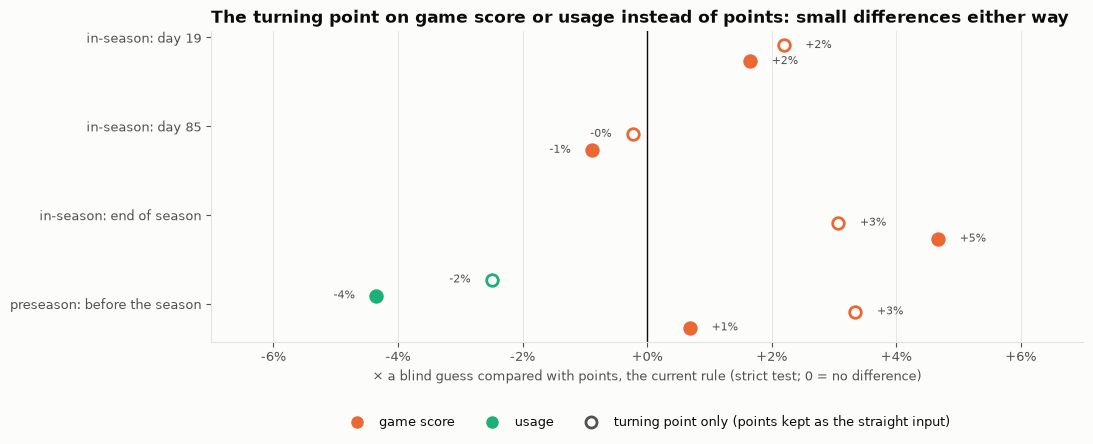

In [5]:
# chart: each variant against points (the current rule), strict test, on one shared scale
COL = {"points": SERIES[0], "game score": SERIES[1], "usage": SERIES[2]}
s = R[R["test"] == "strict"].copy()
s["family"] = s["variant"].str.extract(r"^(points|game score|usage)")[0]
s["only"] = s["variant"].str.contains("turning point only")
base = s[s["variant"] == "points (current)"].set_index(["model", "point"])["× a blind guess"]
s["vs points"] = s["× a blind guess"] / [base[(m, p)] for m, p in zip(s["model"], s["point"])] - 1
s = s[s["variant"] != "points (current)"]
order = [("in-season", "day 19"), ("in-season", "day 85"), ("in-season", "end of season"), ("preseason", "before the season")]
names = list(dict.fromkeys(s["variant"]))
fig, ax = plt.subplots(figsize=(11, 4.6))
ys = {o: len(order) - 1 - j for j, o in enumerate(order)}
offs = dict(zip(names, np.linspace(-0.27, 0.27, len(names))))
for _, r in s.iterrows():
    c = COL[r["family"]]; y = ys[(r["model"], r["point"])] + offs[r["variant"]]
    ax.scatter(r["vs points"] * 100, y, s=70, color=SURFACE if r["only"] else c, edgecolor=c, linewidth=2, zorder=3)
    ax.text(r["vs points"] * 100 + (0.35 if r["vs points"] >= 0 else -0.35), y, f"{r['vs points']:+.0%}", va="center",
            ha="left" if r["vs points"] >= 0 else "right", fontsize=8, color=INK2)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(list(ys.values()), [f"{m}: {p}" for m, p in ys], fontsize=9.5)
lim = max(6, np.ceil(abs(s["vs points"]).max() * 100) + 2)
ax.set_xlim(-lim, lim); ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.set_xlabel("× a blind guess compared with points, the current rule (strict test; 0 = no difference)")
ax.grid(axis="y", visible=False)
ax.set_title("The turning point on game score or usage instead of points: small differences either way", loc="left", fontsize=12, fontweight="bold")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=COL[k], label=k) for k in ("game score", "usage")]
handles += [plt.Line2D([], [], marker="o", linestyle="", markersize=8, markerfacecolor=SURFACE, markeredgecolor=INK2, markeredgewidth=2, label="turning point only (points kept as the straight input)")]
ax.legend(handles=handles, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "21_turning_point_measures.png", dpi=150, bbox_inches="tight")
plt.show()

### 21B findings (12 November 2026)

**1. By the rule written before the results, game score replaces points in the live race, and points stay before the season.**
- **In-season, strict test:** game score beat points at day 19 (6.3× → 6.4× a blind guess, the same 11 winners in the top 7) and at season's end (23.4× → 24.4×, the same 17), and lost narrowly at day 85 (19.4× → 19.2×, one fewer winner in the top 7). Two of three: it replaces points (**D41**).
- **The leave-one-out test agrees:** game score is level or better at every point (day 19 8.1× → 8.3×, with one more winner in the top 7; season's end 35.0× → 35.3×).
- **Before the season, nothing beat points** without losing a winner from the top 7. Usage was the weakest (5.7× → 5.4×).

**2. The differences are small, and that is the finding.** Every change is within ±5%. Baseline points and game score correlate at 0.955: for established players they are nearly the same measure. Voters discount players who are already *established*, whether that comes from scoring or from all-round production. The rule was never really a points crutch.

**3. Where the turning point sits.** The data chose game score 14 most often (about an 18-point scorer, at the same share of candidates), against 20 points before. No winner since 2000-01 had a baseline game score above 14.6.

**4. What it does not do.** In the live race, the straight input on the baseline game score and the turning point nearly cancel above 14: each extra point of baseline game score lowers the odds only slightly. So the turning point *neutralises* a star's high level rather than counting it against him, and an elite player with a big jump (Victor Wembanyama this season) can still rank highly. Since 2000-01, 75 candidates had a baseline game score of 22 or more; 5 got votes and none finished in the top 5. Testing an "already clearly a star" input is next (TODO, B2b).
